# Feature Distribution Analysis for Credit Default Risk.

The target variable is `SeriousDlqin`:

- `0`: no serious delinquency
- `1`: serious delinquency

# Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


##  Load the data

In [3]:
data= pd.read_csv("GiveMeSomeCredit.csv")

print("shape", data.shape)
data.head(10)

shape (149724, 14)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1
5,1,1.459344,54,F,3,3,1718.000000,NaN,18,9,0,7,0.0,2
6,1,14.540918,45,F,3,3,1.151865,3726.0,11,0,2,7,3.0,3
7,1,0.915053,48,M,2,1,0.652057,2600.0,8,0,1,7,0.0,3
8,1,1.000000,31,F,2,0,503.000000,NaN,4,7,0,7,0.0,2
9,0,1.445042,38,F,3,0,0.136132,4715.0,5,3,0,7,2.0,0


In [4]:
df=data.copy()

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   age                                   149724 non-null  int64  
 3   SEX                                   149724 non-null  object 
 4   EDUCATION                             149724 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  149724 non-null  int64  
 6   DebtRatio                             149724 non-null  float64
 7   MonthlyIncome                         120117 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       149724 non-null  int64  
 9   NumberOfTimes90DaysLate               149724 non-null  int64  
 10  NumberRealEstateLoansOrLines          149724 non-null  int64  
 11  

In [6]:
df["SEX"] = df["SEX"].map({
    "M": 0,
    "F": 1
})

##  Target distribution

In [7]:
target = "SeriousDlqin"

print("Target:", target)
print("Unique values:")
print(df[target].unique())

Target: SeriousDlqin
Unique values:
[1 0]


In [8]:
target_summary = pd.DataFrame({
    "Count": df[target].value_counts(),
    "Percent": df[target].value_counts(normalize=True).mul(100).round(2)
})

target_summary

,Count,Percent
SeriousDlqin,,
0,139845,93.4
1,9879,6.6


In [9]:
duplicate_count = df.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)

Number of duplicated rows: 142


In [10]:
df[df.duplicated(keep=False)]

,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
30045,0,1.0,32,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30050,0,1.0,32,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30067,0,1.0,37,1,3,0,0.0,NaN,0,1,0,0,0.0,0
30070,0,1.0,37,1,3,0,0.0,NaN,0,1,0,0,0.0,0
121347,0,1.0,22,1,1,0,0.0,929.0,1,0,0,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149706,0,0.0,42,0,3,0,0.0,NaN,2,0,0,0,0.0,0
149709,0,0.0,79,1,3,0,0.0,NaN,1,0,0,0,NaN,0
149714,0,0.0,23,1,2,0,0.0,NaN,2,0,0,0,0.0,0
149717,0,0.0,59,1,1,0,0.0,NaN,1,0,0,0,0.0,0


In [11]:
corr = df.corr()

corr[target].sort_values(ascending=False)

SeriousDlqin                            1.000000
NumberOfDefault                         0.921535
NumberOfTimes90DaysLate                 0.314557
NumberOfTime30-59DaysPastDueNotWorse    0.274554
NumberOfTime60-89DaysPastDueNotWorse    0.268128
NumberOfDependents                      0.047442
EDUCATION                               0.002214
RevolvingUtilizationOfUnsecuredLines   -0.001625
SEX                                    -0.002724
NumberRealEstateLoansOrLines           -0.003895
DebtRatio                              -0.008778
MonthlyIncome                          -0.023343
NumberOfOpenCreditLinesAndLoans        -0.024219
age                                    -0.112966
Name: SeriousDlqin, dtype: float64

In [12]:
print(df[["NumberOfDefault", target]].head(20))

    NumberOfDefault  SeriousDlqin
0                 1             1
1                 0             0
2                 0             0
3                 2             1
4                 1             1
5                 2             1
6                 3             1
7                 3             1
8                 2             1
9                 0             0
10                0             0
11                0             0
12                0             0
13                0             0
14                3             1
15                1             1
16                2             1
17                0             0
18                2             1
19                2             1


In [13]:
df = df.drop(columns=["NumberOfDefault"])

print("Leaked feature removed.")

Leaked feature removed.


##  Feature Distribution Analysis

### تحلیل توزیع ویژگی‌ها

In this section, we analyze three selected features to understand their
distributions, missing values, zero values, potential outliers, and
relationships with credit default status.

در این بخش، سه ویژگی منتخب را بررسی می‌کنیم تا توزیع داده‌ها،
مقادیر گمشده، مقادیر صفر، داده‌های پرت بالقوه و ارتباط آن‌ها
با وضعیت نکول اعتباری را بشناسیم.

Selected features:
- NumberOfTimes90DaysLate
- RevolvingUtilizationOfUnsecuredLines
- MonthlyIncome

In [14]:
# ویژگی‌های منتخب و متغیر هدف را در یک دیتافریم جداگانه قرار می‌دهیم.
target = "SeriousDlqin"

features = [
    "NumberOfTimes90DaysLate",
    "RevolvingUtilizationOfUnsecuredLines",
    "MonthlyIncome"
]

feature_df = data[features + [target]].copy()

print("Dataset shape:", feature_df.shape)
feature_df.head()

Dataset shape: (149724, 4)


,NumberOfTimes90DaysLate,RevolvingUtilizationOfUnsecuredLines,MonthlyIncome,SeriousDlqin
0,2,0.878881,12000.0,1
1,0,1.000000,0.0,0
2,6,0.470085,15916.0,0
3,1,0.908082,6500.0,1
4,1,1.000000,2200.0,1


 # بررسی ساختار داده‌ها   

In [15]:
feature_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 4 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   NumberOfTimes90DaysLate               149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   MonthlyIncome                         120117 non-null  float64
 3   SeriousDlqin                          149724 non-null  int64  
dtypes: float64(2), int64(2)
memory usage: 4.6 MB


In [16]:
feature_summary = feature_df[features].describe().T

feature_summary

,count,mean,std,min,25%,50%,75%,max
NumberOfTimes90DaysLate,149724.0,0.090446,0.485513,0.0,0.000000,0.000000,0.000000,17.0
RevolvingUtilizationOfUnsecuredLines,149724.0,5.719113,212.891876,0.0,0.029774,0.153492,0.555611,29110.0
MonthlyIncome,120117.0,6650.027190,11493.934709,0.0,3400.000000,5400.000000,8250.000000,1794060.0


# بررسی مقادیر گمشده

In [17]:
missing_summary = pd.DataFrame({
    "Missing_Count": feature_df[features].isnull().sum(),
    "Missing_Percent": (
        feature_df[features].isnull().mean().mul(100).round(2)
    )
})

missing_summary.sort_values(
    "Missing_Percent",
    ascending=False
)

,Missing_Count,Missing_Percent
MonthlyIncome,29607,19.77
NumberOfTimes90DaysLate,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00


# بررسی تعداد و درصد مقادیر صفر

In [18]:
zero_report = pd.DataFrame({
    "Zero_Count": (feature_df[features] == 0).sum(),
    "Zero_Percent": (
        (feature_df[features] == 0).mean().mul(100).round(2)
    )
})

zero_report.sort_values(
    "Zero_Percent",
    ascending=False
)

,Zero_Count,Zero_Percent
NumberOfTimes90DaysLate,141656,94.61
RevolvingUtilizationOfUnsecuredLines,10877,7.26
MonthlyIncome,1627,1.09


در ویژگی NumberOfTimes90DaysLate، مقدار صفر معمولاً به معنی نبود تأخیر ثبت‌شده بیش از ۹۰ روز است. برای درآمد ماهانه و میزان استفاده از اعتبار، صفر باید جداگانه بررسی و تفسیر شود.

# بررسی چولگی توزیع‌ها

In [19]:
skewness = feature_df[features].skew()

skewness = skewness.to_frame(name="Skewness")

skewness

,Skewness
NumberOfTimes90DaysLate,9.335401
RevolvingUtilizationOfUnsecuredLines,67.709674
MonthlyIncome,75.483572


چولگی مثبت بزرگ نشان می‌دهد که توزیع احتمالاً دنباله بلندی در سمت راست دارد. برای نتیجه‌گیری درباره شکل توزیع، این شاخص را همراه با هیستوگرام و میانه بررسی میکنم.

### فراوانی تعداد تأخیرهای بیش از ۹۰ روز

In [20]:
late_counts = feature_df[
    "NumberOfTimes90DaysLate"
].value_counts().sort_index()

late_counts.to_frame(name="Count")

,Count
NumberOfTimes90DaysLate,
0,141656
1,5243
2,1554
3,667
4,291
5,131
6,80
7,38
8,21


### نمودار توزیع تأخیرهای بیش از ۹۰ روز

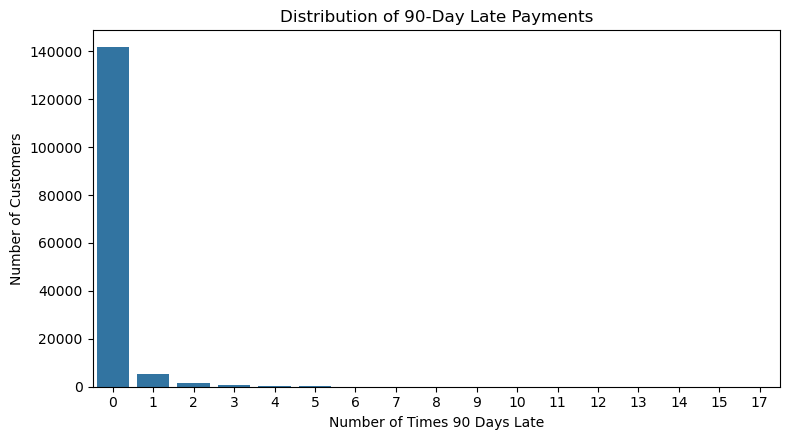

In [21]:

plt.figure(figsize=(8, 4.5))

sns.countplot(
    data=feature_df,
    x="NumberOfTimes90DaysLate"
)

plt.title("Distribution of 90-Day Late Payments")
plt.xlabel("Number of Times 90 Days Late")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## بررسی نرخ نکول بر اساس وجود تأخیر

In [22]:
feature_df["Has90DaysLate"] = (
    feature_df["NumberOfTimes90DaysLate"] > 0
).astype(int)

late_risk = feature_df.groupby("Has90DaysLate")[target].agg(
    Customers="count",
    Defaults="sum",
    Default_Rate="mean"
)

late_risk["Default_Rate"] = (
    late_risk["Default_Rate"].mul(100).round(2)
)

late_risk

,Customers,Defaults,Default_Rate
Has90DaysLate,,,
0,141656,6554,4.63
1,8068,3325,41.21



توزیع این ویژگی نشان می‌دهد که مشتریان چند بار تأخیر بیش از
۹۰ روز داشته‌اند. مقایسه نرخ نکول کمک می‌کند مشخص شود آیا
داشتن حداقل یک تأخیر از این نوع با نرخ نکول مشاهده‌شده بالاتر
همراه است یا خیر.

این مقایسه نشان‌دهنده ارتباط آماری است و به‌تنهایی رابطه علت‌ومعلولی
را اثبات نمی‌کند.

# بررسی آماری میزان استفاده از اعتبار

In [23]:
feature_df["RevolvingUtilizationOfUnsecuredLines"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame(name="Value")

,Value
count,149724.000000
mean,5.719113
std,212.891876
min,0.000000
25%,0.029774
50%,0.153492
75%,0.555611
90%,0.977994
95%,1.000000
99%,1.093233


# هیستوگرام میزان استفاده از اعتبار

Text(0.5, 0, 'Revolving Utilization of Unsecured Lines')

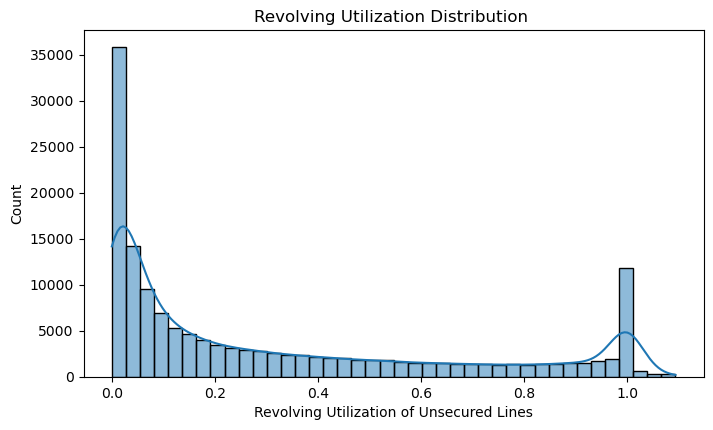

In [25]:
utilization = feature_df[
    "RevolvingUtilizationOfUnsecuredLines"
].quantile(0.99)

plt.figure(figsize=(8, 4.5))

sns.histplot(
    data=feature_df[
        feature_df["RevolvingUtilizationOfUnsecuredLines"]
        <= utilization
    ],
    x="RevolvingUtilizationOfUnsecuredLines",
    bins=40,
    kde=True
)

plt.title("Revolving Utilization Distribution ")
plt.xlabel("Revolving Utilization of Unsecured Lines")

 بلندترین ستون نزدیک ۰ (استفاده بسیار کم از اعتبار) و یک قله مجزا در حوالی ۱ (استفاده کامل از سقف اعتبار؛ صدک ۹۵ دقیقاً ۱ است). بین این دو، تراکم به‌تدریج کم می‌شود و بعد از ۱ ناگهان افت می‌کند. میانه ۰٫۱۵ است، یعنی نیمی از مشتریان کمتر از ۱۵٪ سقف اعتبارشان را استفاده کرده‌اند

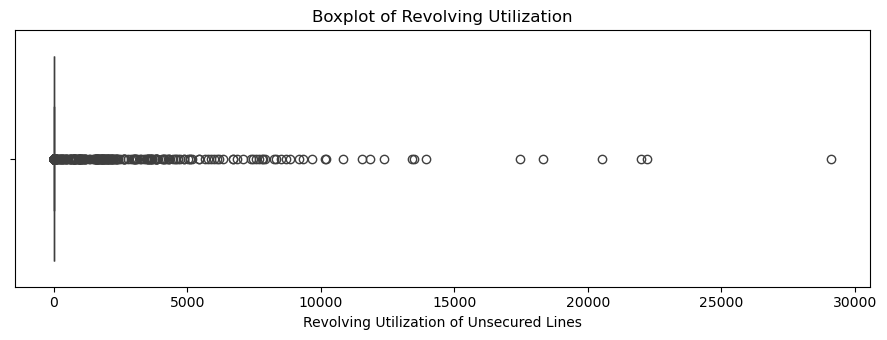

In [26]:

plt.figure(figsize=(9, 3.5))

sns.boxplot(
    x=feature_df["RevolvingUtilizationOfUnsecuredLines"]
)

plt.title("Boxplot of Revolving Utilization")
plt.xlabel("Revolving Utilization of Unsecured Lines")
plt.tight_layout()
plt.show()

چون این متغیر نسبت است، مقادیر خیلی بزرگ‌تر از ۱ احتمالاً خطای ثبت یا سقف اعتبار بسیار کوچک‌اند و باید بررسی شوند

# محاسبه حدود پرت با روش IQR

In [28]:
utilization_q1 = feature_df[
    "RevolvingUtilizationOfUnsecuredLines"
].quantile(0.25)

utilization_q3 = feature_df[
    "RevolvingUtilizationOfUnsecuredLines"
].quantile(0.75)

utilization_iqr = utilization_q3 - utilization_q1

utilization_lower = utilization_q1 - 1.5 * utilization_iqr
utilization_upper = utilization_q3 + 1.5 * utilization_iqr

utilization_outliers = feature_df[
    (
        feature_df["RevolvingUtilizationOfUnsecuredLines"]
        < utilization_lower
    )
    |
    (
        feature_df["RevolvingUtilizationOfUnsecuredLines"]
        > utilization_upper
    )
]

print("Q1:", utilization_q1)
print("Q3:", utilization_q3)
print("IQR:", utilization_iqr)
print("Lower bound:", utilization_lower)
print("Upper bound:", utilization_upper)
print("Potential outliers:", len(utilization_outliers))
print(
    "Potential outliers (%):",
    round(len(utilization_outliers) / len(feature_df) * 100, 2)
)

Q1: 0.029774487
Q3: 0.555611386
IQR: 0.5258368990000001
Lower bound: -0.7589808615000001
Upper bound: 1.3443667345
Potential outliers: 768
Potential outliers (%): 0.51


# بررسی درآمد ماهانه و مقادیر گمشده

In [29]:
feature_df["MonthlyIncome"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    1.201170e+05
mean     6.650027e+03
std      1.149393e+04
min      0.000000e+00
25%      3.400000e+03
50%      5.400000e+03
75%      8.250000e+03
90%      1.166600e+04
95%      1.459340e+04
99%      2.500000e+04
max      1.794060e+06
Name: MonthlyIncome, dtype: float64

In [36]:
print("MonthlyIncome < 0:", (df["MonthlyIncome"] < 0).sum())

MonthlyIncome < 0: 0


# هیستوگرام

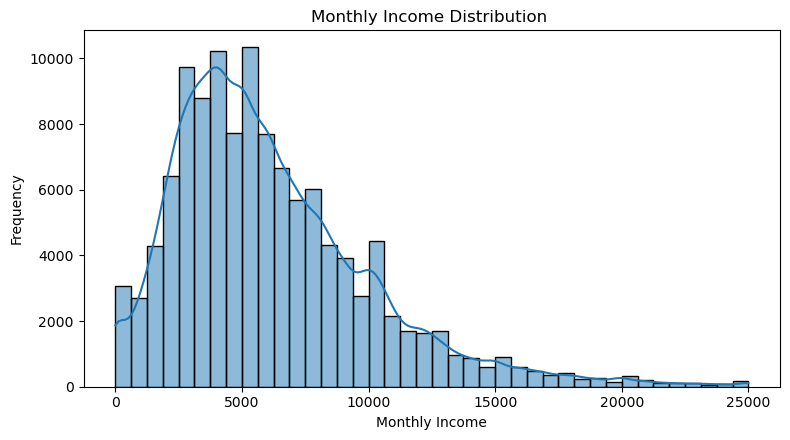

In [37]:

income = feature_df["MonthlyIncome"].quantile(0.99)

plt.figure(figsize=(8, 4.5))

sns.histplot(
    data=feature_df[
        feature_df["MonthlyIncome"] <= income
    ],
    x="MonthlyIncome",
    bins=40,
    kde=True
)

plt.title("Monthly Income Distribution ")
plt.xlabel("Monthly Income")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

 توزیع تک‌قله و راست‌چوله است: بیشترین تراکم بین حدود ۲٬۵۰۰ تا ۶٬۰۰۰ است و بعد از ≈ ۱۰٬۰۰۰ دنباله باریکی تا ۲۵٬۰۰۰ ادامه دارد.

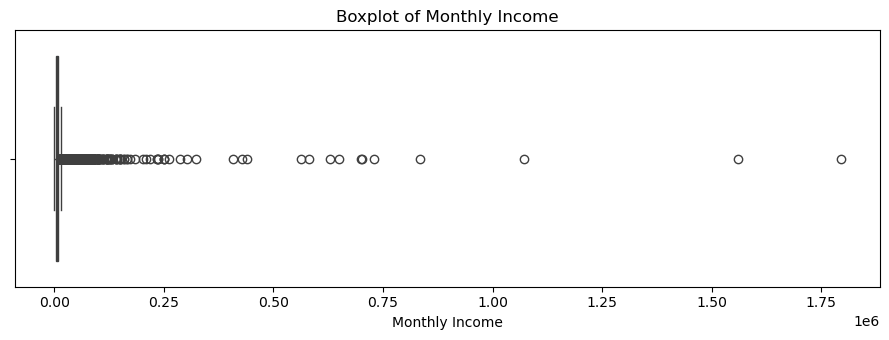

In [31]:
plt.figure(figsize=(9, 3.5))

sns.boxplot(
    x=feature_df["MonthlyIncome"]
)

plt.title("Boxplot of Monthly Income")
plt.xlabel("Monthly Income")
plt.tight_layout()
plt.show()

این پرت‌ها تا حدود ۳۰۰ هزار تقریباً پیوسته‌اند (احتمالاً دنباله بلند توزیع) و فقط تعداد کمی بسیار دورند (بالای ۵۰۰ هزار) که باید جداگانه بررسی شوند
محور تا ≈ ۱٫۸ میلیون کشیده شده (حداکثر ≈ ۱٫۷۹ میلیون) و جعبه به یک خط باریک نزدیک ۰ فشرده شده؛


 # بررسی مقادیر پرت درآمد

In [32]:
income_q1 = feature_df["MonthlyIncome"].quantile(0.25)
income_q3 = feature_df["MonthlyIncome"].quantile(0.75)

income_iqr = income_q3 - income_q1

income_lower = income_q1 - 1.5 * income_iqr
income_upper = income_q3 + 1.5 * income_iqr

income_outliers = feature_df[
    (feature_df["MonthlyIncome"] < income_lower)
    |
    (feature_df["MonthlyIncome"] > income_upper)
]

print("Q1:", income_q1)
print("Q3:", income_q3)
print("IQR:", income_iqr)
print("Lower bound:", income_lower)
print("Upper bound:", income_upper)
print("Potential outliers:", len(income_outliers))
print(
    "Potential outliers (%):",
    round(len(income_outliers) / feature_df["MonthlyIncome"].notna().sum() * 100, 2)
)

Q1: 3400.0
Q3: 8250.0
IQR: 4850.0
Lower bound: -3875.0
Upper bound: 15525.0
Potential outliers: 4875
Potential outliers (%): 4.06


### مقایسه درآمد میان دو گروه نکول

In [33]:
income_by_default = feature_df.groupby(target)["MonthlyIncome"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std="std"
)

income_by_default

,Count,Mean,Median,Std
SeriousDlqin,,,,
0,111844,6722.996933,5470.0,11788.520334
1,8273,5663.537653,4500.0,6192.521022


### مقایسه توزیع درآمد میان دو گروه

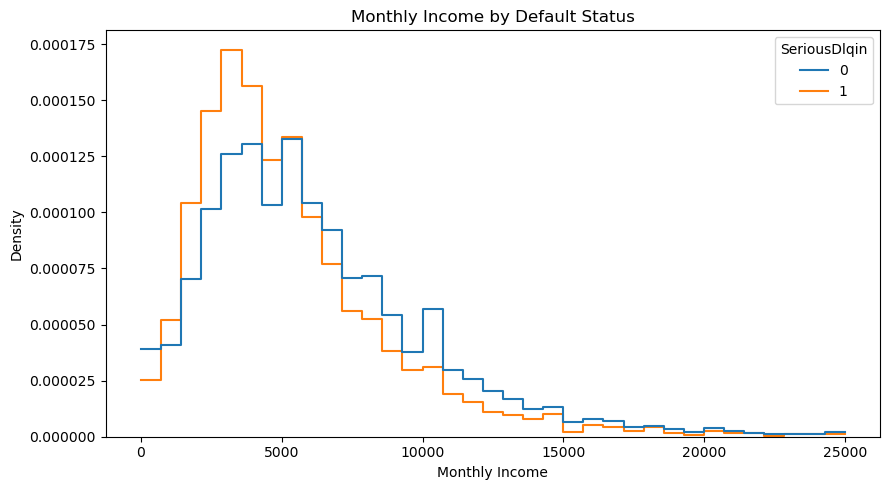

In [35]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=feature_df[
        feature_df["MonthlyIncome"] <= income
    ],
    x="MonthlyIncome",
    hue=target,
    bins=35,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Monthly Income by Default Status")
plt.xlabel("Monthly Income")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

پس تفاوت اندازه گروه‌ها روی ارتفاع اثر ندارد. این الگو با میانه ۴٬۵۰۰ (نکول) در برابر ۵٬۴۷۰ (بدون نکول) سازگار است، اما همپوشانی دو توزیع زیاد است.

###  MonthlyIncome

در ویژگی درآمد ماهانه مقادیر گمشده وجود دارد؛ بنابراین تعداد
مشاهدات معتبر باید همراه با آمار توصیفی گزارش شود. هیستوگرام،
چولگی و نمودار جعبه‌ای برای بررسی عدم تقارن توزیع و درآمدهای
بسیار بزرگ به کار می‌روند.

تفاوت درآمد مشتریان دارای نکول و بدون نکول باید با توجه به
میانگین و میانه مشاهده‌شده تفسیر شود. این تفاوت‌ها به‌تنهایی
رابطه علت‌ومعلولی را ثابت نمی‌کنند.

## نتیجه‌گیری

- **تأخیر ۹۰ روزه:** نرخ نکول در مشتریان با حداقل یک تأخیر ۴۱٫۲۱٪ و در بقیه ۴٫۶۳٪ است (≈ ۹ برابر). اما فقط ≈ ۵٫۴٪ مشتریان (۸٬۰۶۸ نفر) این سابقه را دارند و فقط ≈ ۳۴٪ نکول‌ها (۳٬۳۲۵ از ۹٬۸۷۹) در میان آن‌ها هستند؛ پس این ویژگی به‌تنهایی بیشتر نکول‌ها را پوشش نمی‌دهد.
- **میزان استفاده از اعتبار:** توزیع دو قله‌ای (نزدیک ۰ و ۱) با پرت‌های بسیار بزرگ (تا ۲۹٬۱۱۰)؛ مقادیر بالاتر از ۱ باید بررسی و پیش از مدل‌سازی مهار (capping) شوند. رابطه این ویژگی با نکول در این نوت‌بوک بررسی نشده است.
- **درآمد ماهانه:** راست‌چوله با ۱۹٫۷۷٪ مقدار گمشده و ۱٬۶۲۷ مقدار صفر. میانه گروه نکول کمتر است (۴٬۵۰۰ در برابر ۵٬۴۷۰) اما همپوشانی توزیع‌ها زیاد است؛ پس درآمد به‌تنهایی جداکننده قوی نیست.
- همه یافته‌ها ارتباط آماری‌اند، نه علیت؛ و چون فقط ۶٫۶٪ مشتریان نکول دارند، داده نامتوازن است.